# FraudLens — Exploratory Data Analysis

Focused EDA on the transaction data that feeds the fraud model: class
balance, amount/time distributions, data quality, and why accuracy is the
wrong metric to optimize for this problem. See `data/raw/README.md` for
which dataset (synthetic sample vs. the real Kaggle file) is currently
configured — the cell below prints which one this run used.

In [1]:
import sys
from pathlib import Path

# nbconvert executes with cwd = the notebook's own directory.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import plotly.express as px
import plotly.io as pio

from src.utils.config import settings

pio.renderers.default = "png"  # static images so charts render on GitHub

df = pd.read_csv(settings.raw_data_path)
is_real_dataset = settings.raw_data_path.name == "creditcard.csv"

print(f"Loaded: {settings.raw_data_path.name} (storage mode: {settings.storage_mode})")
print(f"Shape: {df.shape}")
print("Dataset: REAL Kaggle file" if is_real_dataset else "Dataset: SYNTHETIC sample - see data/raw/README.md")

Loaded: creditcard_sample.csv (storage mode: local)
Shape: (24145, 31)
Dataset: SYNTHETIC sample - see data/raw/README.md


## Class distribution

Fraud is a tiny fraction of transactions by design — that imbalance drives every modeling decision downstream.

Class
legitimate    24025
fraud           120
Name: count, dtype: int64

Fraud rate: 0.4970%


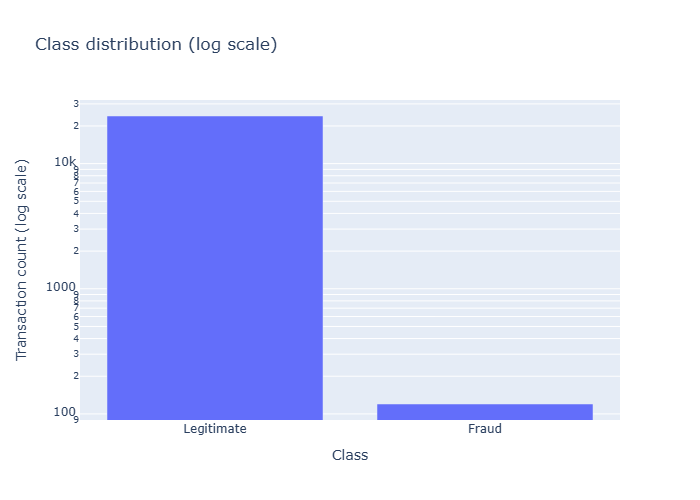

In [2]:
class_counts = df["Class"].value_counts().sort_index()
fraud_rate = 100 * class_counts.get(1, 0) / len(df)
print(class_counts.rename({0: "legitimate", 1: "fraud"}))
print(f"\nFraud rate: {fraud_rate:.4f}%")

fig = px.bar(
    x=["Legitimate", "Fraud"],
    y=[int(class_counts.get(0, 0)), int(class_counts.get(1, 0))],
    log_y=True,
    labels={"x": "Class", "y": "Transaction count (log scale)"},
    title="Class distribution (log scale)",
)
fig.show()

## Why accuracy is misleading

With fraud under 1% of transactions, a classifier that never predicts
fraud still scores extremely high accuracy while catching nothing. The
cell below makes that concrete on this dataset.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

X = df.drop(columns=["Class"])
y = df["Class"]

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X, y)
pred = dummy.predict(X)

print(f"'Always predict legitimate' accuracy:        {accuracy_score(y, pred):.4%}")
print(f"'Always predict legitimate' recall on fraud:  {recall_score(y, pred):.4%}")
print(
    "\nAccuracy looks excellent; recall shows it catches zero fraud. "
    "This is why model comparison (src/models/evaluate.py) leads with "
    "precision, recall, F1, and PR-AUC instead of accuracy."
)

'Always predict legitimate' accuracy:        99.5030%
'Always predict legitimate' recall on fraud:  0.0000%

Accuracy looks excellent; recall shows it catches zero fraud. This is why model comparison (src/models/evaluate.py) leads with precision, recall, F1, and PR-AUC instead of accuracy.


## Transaction amount

Overall distribution, then split by class.

count    24145.000000
mean        37.075781
std         55.720855
min          0.340000
25%          9.640000
50%         20.040000
75%         42.610000
max       2135.060000
Name: Amount, dtype: float64


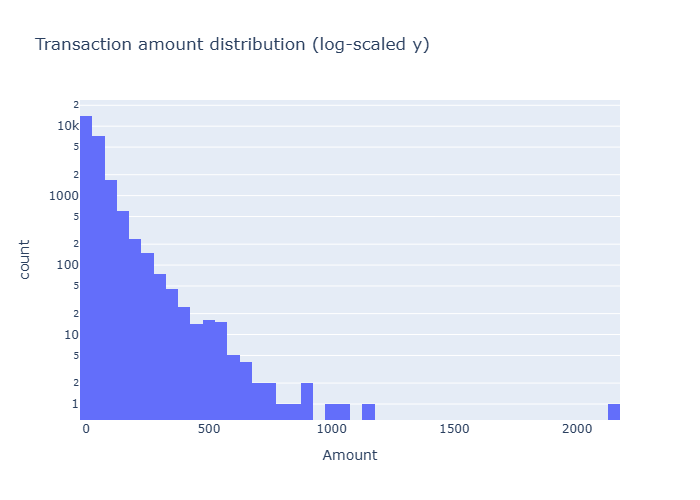

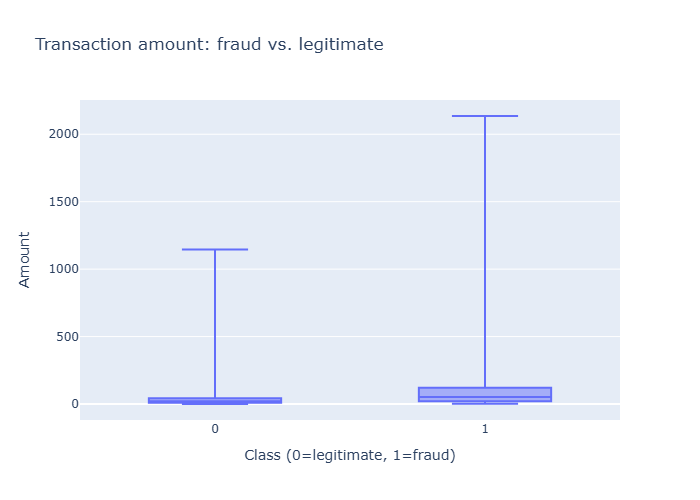

         count        mean         std   min      25%    50%       75%  \
Class                                                                    
0      24025.0   36.651437   52.854237  0.34   9.6300  19.98   42.4000   
1        120.0  122.033000  242.179076  1.71  21.0325  52.91  119.6575   

           max  
Class           
0      1146.06  
1      2135.06  


In [4]:
print(df["Amount"].describe())

fig = px.histogram(df, x="Amount", nbins=60, log_y=True, title="Transaction amount distribution (log-scaled y)")
fig.show()

fig = px.box(
    df, x="Class", y="Amount", points=False,
    labels={"Class": "Class (0=legitimate, 1=fraud)"},
    title="Transaction amount: fraud vs. legitimate",
)
fig.show()

print(df.groupby("Class")["Amount"].describe())

## Transaction timing

`Time` is elapsed seconds since the first transaction in the batch. Folding
it to hour-of-day shows whether fraud clusters at particular times.

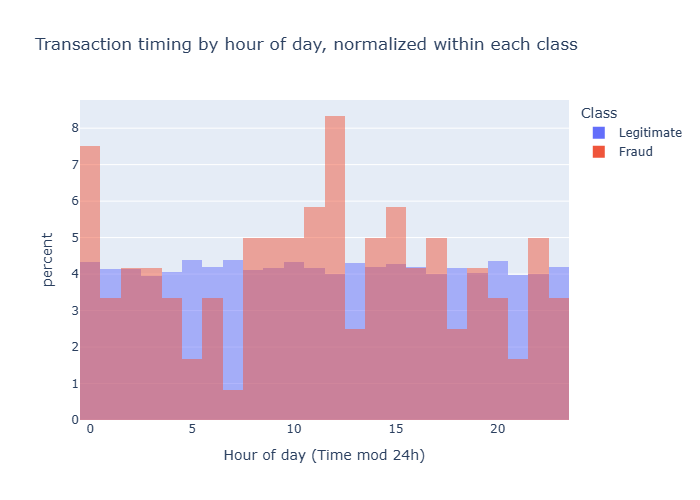

In [5]:
df["hour"] = (df["Time"] % 86400) // 3600

fig = px.histogram(
    df, x="hour", color=df["Class"].map({0: "Legitimate", 1: "Fraud"}),
    barmode="overlay", nbins=24, histnorm="percent",
    labels={"hour": "Hour of day (Time mod 24h)", "color": "Class"},
    title="Transaction timing by hour of day, normalized within each class",
)
fig.show()

## Missing values and duplicates

In [6]:
missing = df.isna().sum()
missing = missing[missing > 0]
print("Columns with missing values:" if len(missing) else "No missing values in any column.")
print(missing)

duplicate_count = int(df.duplicated().sum())
print(f"\nExact duplicate rows: {duplicate_count} ({100 * duplicate_count / len(df):.3f}% of rows)")

No missing values in any column.
Series([], dtype: int64)

Exact duplicate rows: 25 (0.104% of rows)


## Feature distributions (V1-V28)

`V1`-`V28` are PCA-anonymized in the real dataset (and modeled as
independent Gaussian components in the synthetic sample) — they carry no
disclosed real-world meaning such as merchant, location, or device, and
nothing in this project assigns them one. The check below just identifies
which components separate the two classes most, to confirm the data has
learnable signal before building a model on it.

Largest mean shift between classes (top 8 components):
V3     2.493918
V1     2.476845
V5     2.453023
V4     2.348513
V14    2.301746
V2     2.271888
V9     2.256051
V17    0.175557
Name: 1, dtype: float64


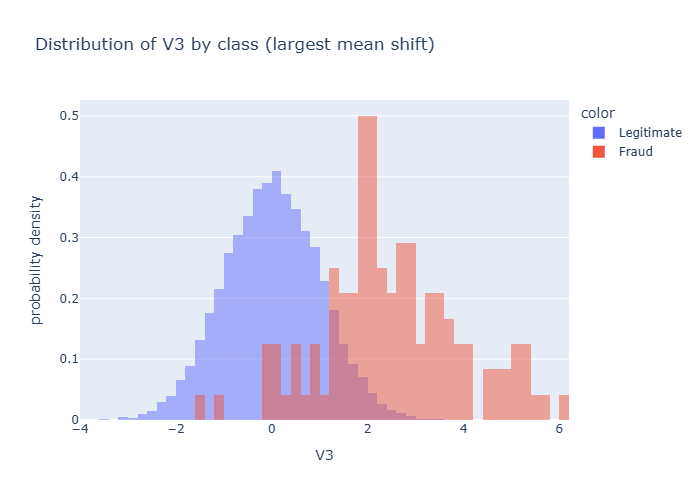

In [7]:
v_cols = [c for c in df.columns if c.startswith("V")]
separation = df.groupby("Class")[v_cols].mean().diff().abs().iloc[-1].sort_values(ascending=False)
print("Largest mean shift between classes (top 8 components):")
print(separation.head(8))

top_feature = separation.index[0]
fig = px.histogram(
    df, x=top_feature, color=df["Class"].map({0: "Legitimate", 1: "Fraud"}),
    barmode="overlay", nbins=60, histnorm="probability density",
    title=f"Distribution of {top_feature} by class (largest mean shift)",
)
fig.show()

## Summary

Computed directly from the data loaded above — nothing here is hand-typed.

In [8]:
legit_mean = df.loc[df.Class == 0, "Amount"].mean()
fraud_mean = df.loc[df.Class == 1, "Amount"].mean()

print("Summary")
print("=======")
print(f"- {len(df):,} transactions, {int(class_counts.get(1, 0))} labeled fraud ({fraud_rate:.3f}%).")
print(f"- {duplicate_count} exact duplicate rows detected.")
print(f"- {int(missing.sum())} missing values across all columns.")
print(
    f"- Fraud transactions average ${fraud_mean:.2f} vs. ${legit_mean:.2f} for legitimate "
    f"transactions in this dataset."
)
print(f"- Most class-separating feature: {top_feature}.")
print("- Accuracy is not a usable metric here - see the dummy-classifier cell above.")

Summary
- 24,145 transactions, 120 labeled fraud (0.497%).
- 25 exact duplicate rows detected.
- 0 missing values across all columns.
- Fraud transactions average $122.03 vs. $36.65 for legitimate transactions in this dataset.
- Most class-separating feature: V3.
- Accuracy is not a usable metric here - see the dummy-classifier cell above.
